# Recurrent Neural Networks Demo

## Imports, Random Seed and Device Setup

In [72]:
# Setup & Imports
import os
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (precision_score, recall_score,
                              confusion_matrix, classification_report)

# Fix random seeds so results are reproducible
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

sns.set_theme(style='ticks')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

Using device: cuda


# Loading Human Activity *Recognition* Dataset

In [73]:
zip_url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
zip_path = "/content/human_activity_recognition_using_smartphones.zip"
extract_path = "/content/"

print(f"Downloading from: {zip_url}")
response = requests.get(zip_url, stream=True)
response.raise_for_status() # Raise an exception for HTTP errors

with open(zip_path, "wb") as f:
    for chunk in response.iter_content(chunk_size=8192):
        f.write(chunk)
print(f"Downloaded to: {zip_path}")

# First extraction: extracts 'UCI HAR Dataset.zip' and 'UCI HAR Dataset.names' to /content/
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
print(f"Extracted initial zip to: {extract_path}")

# Now, extract the nested UCI HAR Dataset.zip
nested_zip_path = os.path.join(extract_path, 'UCI HAR Dataset.zip')
nested_extract_path = os.path.join(extract_path, 'UCI HAR Dataset') # This will create the final data directory

if os.path.exists(nested_zip_path):
    with zipfile.ZipFile(nested_zip_path, 'r') as zip_ref:
        zip_ref.extractall(nested_extract_path)
    print(f"Extracted nested dataset to: {nested_extract_path}")
    # Clean up the nested zip file
    os.remove(nested_zip_path)
else:
    print(f"Nested zip file not found: {nested_zip_path}")

# Clean up the original outer zip file
os.remove(zip_path)


Downloaded to: /content/human_activity_recognition_using_smartphones.zip
Extracted initial zip to: /content/
Extracted nested dataset to: /content/UCI HAR Dataset


In [74]:
# Set BASE to the extracted directory, accounting for the top-level folder in the zip
BASE = os.path.join('/content/', 'UCI HAR Dataset/UCI HAR Dataset')

print("Path to dataset files:", BASE)

# The 9 raw signal file name stems
SIGNAL_NAMES = [
    'body_acc_x', 'body_acc_y', 'body_acc_z',
    'body_gyro_x', 'body_gyro_y', 'body_gyro_z',
    'total_acc_x', 'total_acc_y', 'total_acc_z'
]

ACTIVITY_NAMES = {
    1: 'WALKING', 2: 'WALKING_UPSTAIRS', 3: 'WALKING_DOWNSTAIRS',
    4: 'SITTING', 5: 'STANDING', 6: 'LAYING'
}


def load_signal(split: str, signal_name: str) -> np.ndarray:
    """
    Load one sensor channel for one split.
    Returns shape: (N, 128)
    """
    # Removing the 'Inertial Signals/' subdirectory from the path for all signals.
    # This assumes all signal files are directly under BASE/split/
    path = f'{BASE}/{split}/Inertial Signals/{signal_name}_{split}.txt'
    return pd.read_csv(path, sep=r'\s+', header=None).values.astype(np.float32)


def load_all_signals(split: str) -> np.ndarray:
    """
    Load all 9 sensor channels and stack them.
    Returns shape: (N, 128, 9)
    """
    channels = [load_signal(split, s) for s in SIGNAL_NAMES]
    # Each channel is (N, 128) → stack along last axis → (N, 128, 9)
    return np.stack(channels, axis=-1)


def load_labels(split: str) -> np.ndarray:
    path = f'{BASE}/{split}/y_{split}.txt'
    return pd.read_csv(path, sep=r'\s+', header=None).values.ravel().astype(int)


def load_subjects(split: str) -> np.ndarray:
    path = f'{BASE}/{split}/subject_{split}.txt'
    return pd.read_csv(path, sep=r'\s+', header=None).values.ravel().astype(int)


# Load both pre-provided splits so we can re-divide by subject
X_raw_train = load_all_signals('train')
y_raw_train = load_labels('train')
s_raw_train = load_subjects('train')

X_raw_test  = load_all_signals('test')
y_raw_test  = load_labels('test')
s_raw_test  = load_subjects('test')

# Merge into one pool so we can split by subject ourselves
X_all = np.concatenate([X_raw_train, X_raw_test], axis=0)
y_all = np.concatenate([y_raw_train, y_raw_test])
s_all = np.concatenate([s_raw_train, s_raw_test])

print(f'Total samples  : {X_all.shape[0]}')
print(f'Train samples    : {X_raw_train.shape[0]}')
print(f'Test  samples    : {X_raw_test.shape[0]}')
print(f'Sequence length: {X_all.shape[1]} timesteps')
print(f'Sensor channels: {X_all.shape[2]}')
print(f'Subjects       : {np.unique(s_all)}')
print(f'Activity labels: {np.unique(y_all)}')

Path to dataset files: /content/UCI HAR Dataset/UCI HAR Dataset
Total samples  : 10299
Train samples    : 7352
Test  samples    : 2947
Sequence length: 128 timesteps
Sensor channels: 9
Subjects       : [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30]
Activity labels: [1 2 3 4 5 6]


In [75]:
import os

# The zip file was extracted into /content/
# Let's list the contents of /content/ to find the actual dataset directory
print('Listing contents of /content/:')
for item in os.listdir('/content/'):
    full_path = os.path.join('/content/', item)
    if os.path.isdir(full_path):
        print(f'  Directory: {item}')
        # Optionally, list some contents of the top-level directory if found
        # This helps in quickly identifying nested structures
        if item == 'UCI HAR Dataset': # Assume this is the one we are looking for
            print(f'    Contents of {item}:')
            for sub_item in os.listdir(full_path):
                print(f'      - {sub_item}')
    elif os.path.isfile(full_path):
        print(f'  File: {item}')


Listing contents of /content/:
  Directory: .config
  Directory: UCI HAR Dataset
    Contents of UCI HAR Dataset:
      - UCI HAR Dataset
      - __MACOSX
  File: rnn__best.pth
  File: lstm__best.pth
  File: UCI HAR Dataset.names
  Directory: sample_data


# Show the class distribution of the dataset

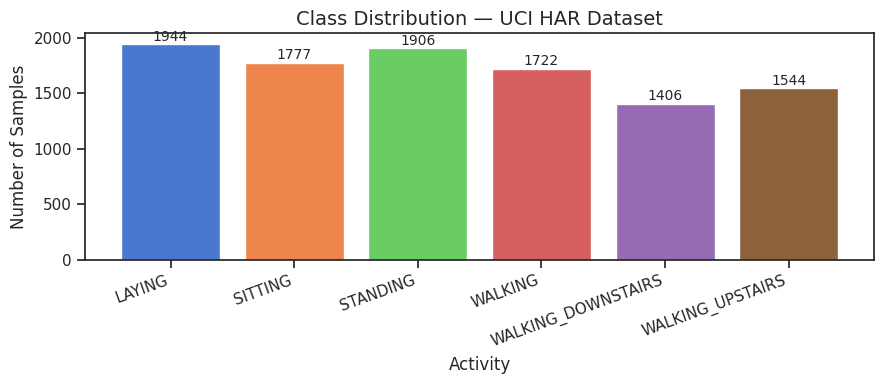

LAYING                1944
SITTING               1777
STANDING              1906
WALKING               1722
WALKING_DOWNSTAIRS    1406
WALKING_UPSTAIRS      1544


In [76]:
# ─────────────────────────────────────────────────────────────────
#  Count how many samples belong to each activity class and plot.
#  This is important for checking whether the dataset is balanced.
# ─────────────────────────────────────────────────────────────────

label_series = pd.Series(y_all).map(ACTIVITY_NAMES)
class_counts = label_series.value_counts().sort_index()

plt.figure(figsize=(9, 4))
bars = plt.bar(class_counts.index, class_counts.values,
               color=sns.color_palette('muted', len(class_counts)))
plt.title('Class Distribution — UCI HAR Dataset', fontsize=14)
plt.xlabel('Activity'); plt.ylabel('Number of Samples')
plt.xticks(rotation=20, ha='right')
for bar, count in zip(bars, class_counts.values):
    plt.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 30, str(count), ha='center', fontsize=10)
plt.tight_layout()
plt.show()
print(class_counts.to_string())

## Visualize Sensor Data

Let's visualize some raw sensor data to get a better feel for the input sequences. We'll pick a random sample and plot its 9 sensor channels over time.

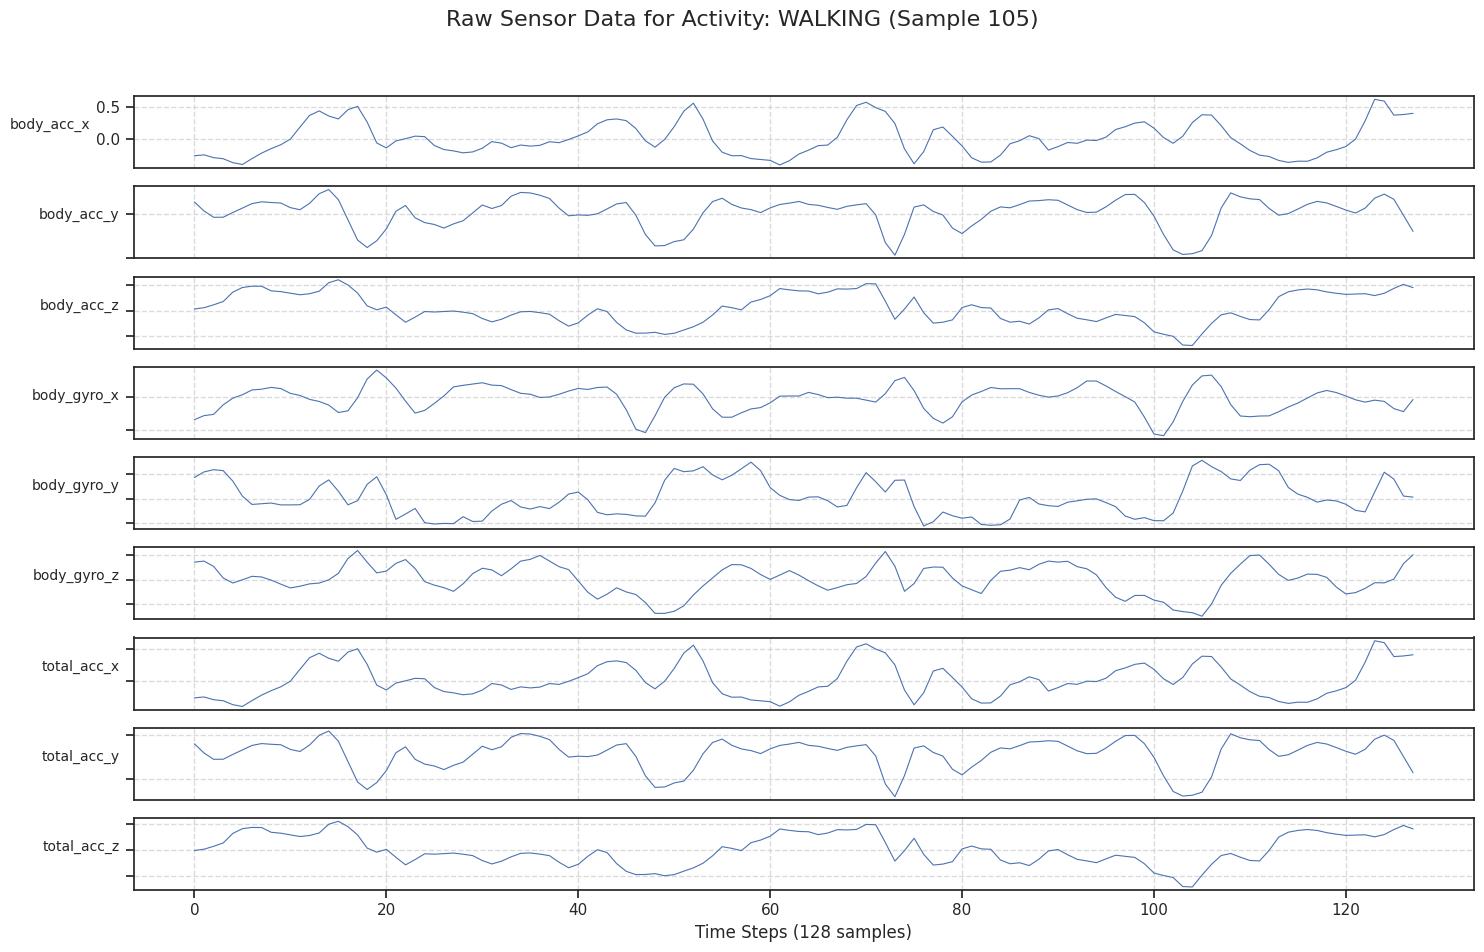

In [77]:
# ─────────────────────────────────────────────────────────────────
#  Visualize raw sensor data for a randomly chosen sample.
# ─────────────────────────────────────────────────────────────────

import numpy as np
import random
import matplotlib.pyplot as plt
import seaborn as sns

# Get a random sample index from the dataset
# (No specific activity filter, just a random sample from the whole set)
sample_idx = random.randint(0, X_all.shape[0] - 1)

# Extract the sensor data and its corresponding activity label
sample_data = X_all[sample_idx] # Shape (128, 9) - 128 timesteps, 9 sensor channels
sample_label = y_all[sample_idx]
sample_activity = ACTIVITY_NAMES[sample_label]

# Create a figure with 9 subplots (one for each sensor channel), sharing the x-axis
fig, axes = plt.subplots(len(SIGNAL_NAMES), 1, figsize=(15, 10), sharex=True)

# Set the main title for the entire figure
fig.suptitle(f'Raw Sensor Data for Activity: {sample_activity} (Sample {sample_idx})',
             fontsize=16, y=0.98)

# Loop through each sensor channel and plot its data
for i, ax in enumerate(axes):
    ax.plot(sample_data[:, i], linewidth=0.8, label=SIGNAL_NAMES[i])
    ax.set_ylabel(SIGNAL_NAMES[i], rotation=0, ha='right', fontsize=10) # Set full signal name as y-label
    ax.grid(True, linestyle='--', alpha=0.7) # Add a grid for readability

    # Hide y-tick labels for all but the first plot to avoid clutter
    if i > 0:
        ax.tick_params(axis='y', labelleft=False)

    # Only show x-axis labels on the last subplot
    if i < len(SIGNAL_NAMES) - 1:
        ax.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False) # Hide x-axis ticks and labels

# Set x-axis label for the bottom-most subplot
axes[-1].set_xlabel('Time Steps (128 samples)', fontsize=12)

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent overlapping titles/labels
plt.show() # Display the plot

## Subject-based Data Splitting

We divide the dataset into training, validation, and test sets based on subject IDs to ensure a robust evaluation. This approach prevents data leakage and ensures that the model is tested on data from subjects it has not seen during training.

In [78]:
all_subjects = np.arange(1, 31)           # subjects 1 - 30

# Fixed, reproducible split
train_subjects = all_subjects[:20]         # subjects  1 – 20
val_subjects   = all_subjects[20:25]       # subjects 21 – 25
test_subjects  = all_subjects[25:]         # subjects 26 – 30

print('Train subjects :', train_subjects)
print('Val   subjects :', val_subjects)
print('Test  subjects :', test_subjects)

Train subjects : [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]
Val   subjects : [21 22 23 24 25]
Test  subjects : [26 27 28 29 30]


In [79]:
# Boolean masks — True where the row belongs to the chosen subjects
train_mask = np.isin(s_all, train_subjects)
val_mask   = np.isin(s_all, val_subjects)
test_mask  = np.isin(s_all, test_subjects)

X_train_raw, y_train = X_all[train_mask], y_all[train_mask]
X_val_raw,   y_val   = X_all[val_mask],   y_all[val_mask]
X_test_raw,  y_test  = X_all[test_mask],  y_all[test_mask]

print(f'\nTrain size : {X_train_raw.shape[0]} samples')
print(f'Val   size : {X_val_raw.shape[0]} samples')
print(f'Test  size : {X_test_raw.shape[0]} samples')


Train size : 6531 samples
Val   size : 1891 samples
Test  size : 1877 samples


In [80]:
# Convert labels to 0-indexed (original labels are 1-6, we need 0-5 for CrossEntropyLoss)
y_train = y_train - 1
y_val   = y_val   - 1
y_test  = y_test  - 1

NUM_CLASSES = 6
SEQ_LEN     = 128   # real time steps
INPUT_SIZE  = 9     # real sensor channels

## Feature Standardization

Standardizing the features (mean-centering and scaling to unit variance) is a crucial preprocessing step for many machine learning models, especially neural networks. It helps ensure that all features contribute equally to the distance calculations and prevents features with larger numerical ranges from dominating the learning process.

In [81]:
# ─────────────────────────────────────────────────────────────────
#  Standardise each of the 9 sensor channels independently.
#
#  Reshape to (N*128, 9) to fit the scaler, then reshape back.
#  Fit ONLY on training data.
# ─────────────────────────────────────────────────────────────────

N_train, T, C = X_train_raw.shape   # e.g. (6531, 128, 9)

scaler = StandardScaler()

# Flatten time into samples for fitting: (N_train * 128, 9)
X_train = scaler.fit_transform(
    X_train_raw.reshape(-1, C)).reshape(N_train, T, C)

X_val = scaler.transform(
    X_val_raw.reshape(-1, C)).reshape(X_val_raw.shape[0], T, C)

X_test = scaler.transform(
    X_test_raw.reshape(-1, C)).reshape(X_test_raw.shape[0], T, C)


print('After standardisation:')
print(f'  Train mean = {X_train.mean():.4f}')
print(f'  Train std  = {X_train.std():.4f}')
print(f'  Val mean = {X_val.mean():.4f}')
print(f'  Test mean = {X_test.mean():.4f}')

After standardisation:
  Train mean = 0.0000
  Train std  = 1.0000
  Val mean = 0.0232
  Test mean = 0.0304


## DataLoader Preparation

We prepare PyTorch DataLoaders for the training, validation, and test datasets. DataLoaders efficiently load data in batches, handle shuffling for training, and convert NumPy arrays to PyTorch tensors, making them ready for model input.

In [82]:
BATCH_SIZE = 64


class HARDataset(Dataset):
    """
    Wraps the flattened HAR feature vectors and reshapes them
    into (seq_len, input_size) tensors expected by RNN/LSTM models.
    """
    def __init__(self, X: np.ndarray, y: np.ndarray,
                 seq_len: int = SEQ_LEN, input_size: int = INPUT_SIZE):
        # Reshape X from (N, 128, 9) to (N, seq_len, input_size) if not already done, or simply convert to tensor
        self.X = torch.tensor(X, dtype=torch.float32) # X is already shaped as (N, seq_len, input_size)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        # Returns the total number of samples in the dataset
        return len(self.y)

    def __getitem__(self, idx):
        # Returns one sample of features (X) and its corresponding label (y)
        return self.X[idx], self.y[idx]


# Build dataset objects for training, validation, and testing
train_dataset = HARDataset(X_train, y_train)
val_dataset   = HARDataset(X_val,   y_val)
test_dataset  = HARDataset(X_test,  y_test)

# Build data loaders for efficient batching and iteration
# shuffle=True for training to randomize batches and improve generalization
# shuffle=False for validation and test to ensure consistent evaluation order
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

# Quick sanity check: Print the shapes of one batch to verify dimensions
X_sample, y_sample = next(iter(train_loader))
print('One batch — X shape:', X_sample.shape) # Expected: (BATCH_SIZE, SEQ_LEN, INPUT_SIZE)
print('One batch — y shape:', y_sample.shape) # Expected: (BATCH_SIZE)

One batch — X shape: torch.Size([64, 128, 9])
One batch — y shape: torch.Size([64])


In [83]:
# ─────────────────────────────────────────────────────────────────
#  Training and evaluation helper function.
#  This function runs a single epoch (either training or validation).
# ─────────────────────────────────────────────────────────────────

EPOCHS   = 50 # Total number of training epochs
LR       = 1e-4 # Learning rate for the optimizer
MAX_NORM = 1.0 # Maximum gradient norm for clipping, to prevent exploding gradients

criterion = nn.CrossEntropyLoss() # Loss function for multi-class classification

def run_epoch(model, loader, optimizer, criterion, is_training: bool):
    """
    Runs one full pass over the data loader for either training or validation.

    Args:
        model (nn.Module): The neural network model to train/evaluate.
        loader (DataLoader): The DataLoader providing data batches.
        optimizer (torch.optim.Optimizer, optional): The optimizer to use for weight updates.
                                                   Required if `is_training` is True.
        criterion (nn.Module): The loss function.
        is_training (bool): If True, the model is in training mode (gradients computed, weights updated).
                            If False, the model is in evaluation mode (no gradient computation).

    Returns:
        tuple: A tuple containing the average loss and accuracy for the epoch.
    """
    # Set model to training mode if `is_training` is True, otherwise set to evaluation mode.
    model.train() if is_training else model.eval()

    total_loss    = 0.0 # Accumulator for total loss across the epoch
    correct_preds = 0   # Accumulator for correctly predicted samples
    total_samples = 0   # Accumulator for total samples processed

    # Use torch.enable_grad() for training and torch.no_grad() for evaluation
    # to efficiently manage gradient computation.
    context = torch.enable_grad() if is_training else torch.no_grad()

    with context:
        # Iterate over each batch in the data loader
        for X_batch, y_batch in loader:
            # Move batch data to the appropriate device (CPU/GPU)
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)                    # Perform forward pass to get raw predictions (logits)
            loss   = criterion(logits, y_batch)        # Compute the loss using the model's output and true labels

            if is_training:
                optimizer.zero_grad()                  # Clear previously computed gradients
                loss.backward()                        # Perform backpropagation to compute gradients
                # Clip gradients to prevent them from exploding, common in RNNs
                nn.utils.clip_grad_norm_(model.parameters(), MAX_NORM)
                optimizer.step()                       # Update model weights based on computed gradients

            # Accumulate statistics for epoch summary
            total_loss    += loss.item() * X_batch.size(0) # Aggregate batch loss, weighted by batch size
            preds          = logits.argmax(dim=1)      # Get the predicted class by finding the index of the max logit
            correct_preds += (preds == y_batch).sum().item() # Count correct predictions
            total_samples += X_batch.size(0) # Accumulate total samples

    avg_loss = total_loss    / total_samples # Calculate average loss for the epoch
    accuracy = correct_preds / total_samples # Calculate accuracy for the epoch
    return avg_loss, accuracy

In [84]:
# ─────────────────────────────────────────────────────────────────
#  Evaluation helper function.
#  This function evaluates the model on the test set and prints
#  classification metrics and a confusion matrix.
# ─────────────────────────────────────────────────────────────────

def evaluate_on_test(model, loader, activity_names):
    """
    Evaluates the given model on the test dataset and prints a detailed
    classification report along with a confusion matrix heatmap.

    Args:
        model (nn.Module): The trained neural network model.
        loader (DataLoader): The DataLoader for the test dataset.
        activity_names (dict): A dictionary mapping activity labels (1-indexed) to names.

    Returns:
        tuple: A tuple containing numpy arrays of all predictions and true labels.
    """
    model.eval() # Set the model to evaluation mode
    all_preds  = [] # List to store all predictions
    all_labels = [] # List to store all true labels

    with torch.no_grad(): # Disable gradient computation for efficiency during evaluation
        for X_batch, y_batch in loader:
            # Move batch data to the appropriate device (CPU/GPU)
            X_batch = X_batch.to(device)
            # Perform forward pass to get raw predictions
            logits = model(X_batch)
            # Get predicted classes and move to CPU for numpy conversion
            preds  = logits.argmax(dim=1).cpu().numpy()
            all_preds.append(preds) # Store predictions
            all_labels.append(y_batch.numpy()) # Store true labels

    # Concatenate all predictions and labels from batches into single arrays
    all_preds  = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)

    # Prepare class names for the classification report and confusion matrix.
    # Labels were converted to 0-indexed (0-5) earlier, so adjust ACTIVITY_NAMES keys.
    class_names = [activity_names[i + 1] for i in range(len(activity_names))]

    # Print a comprehensive classification report (precision, recall, f1-score, support)
    print(classification_report(all_labels, all_preds,
                                  target_names=class_names, digits=4))

    # Calculate per-class precision and recall
    precision = precision_score(all_labels, all_preds, average=None)
    recall    = recall_score(all_labels,    all_preds, average=None)
    print(f'{"Activity":<22}  Precision   Recall') # Header for custom table
    print('-' * 45)
    # Print per-class precision and recall
    for name, p, r in zip(class_names, precision, recall):
        print(f'{name:<22}  {p:.4f}      {r:.4f}')

    # Generate and plot the confusion matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(8, 6)) # Set figure size
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', # Create heatmap with annotations
                xticklabels=class_names, yticklabels=class_names, # Set x and y axis labels
                linewidths=0.5) # Add lines between cells
    plt.title('Confusion Matrix', fontsize=14) # Set title
    plt.xlabel('Predicted Label', fontsize=12) # Set x-axis label
    plt.ylabel('True Label',      fontsize=12) # Set y-axis label
    plt.xticks(rotation=30, ha='right') # Rotate x-axis labels for readability
    plt.tight_layout() # Adjust layout
    plt.show() # Display the plot

    return all_preds, all_labels

## RNN Model

This section implements a Vanilla Recurrent Neural Network (RNN) model using PyTorch's optimized `nn.RNN` layer. We will use a similar architecture to the LSTM model (`HIDDEN_SIZE = 64`, `NUM_LAYERS = 2`, `DROPOUT = 0.4`) to facilitate a fair comparison. The `nn.RNN` layer returns both the output for each time step and the final hidden state. For classification, we are interested in the final hidden state of the last layer.

In [85]:
# ─────────────────────────────────────────────────────────────────
#  Define common hyperparameters for the RNN and LSTM models.
#  These values are chosen to facilitate a fair comparison between models.
# ─────────────────────────────────────────────────────────────────

HIDDEN_SIZE = 64  # Number of features in the hidden state
NUM_LAYERS  = 2   # Number of recurrent layers
DROPOUT     = 0.4 # Dropout rate for regularization

In [86]:
# ─────────────────────────────────────────────────────────────────
#  This section defines a Vanilla RNN model using PyTorch's
#  nn.RNN layer. It mirrors the architecture of the other models
#  for consistent comparison.
# ─────────────────────────────────────────────────────────────────

class RNN(nn.Module):
    """
    Vanilla RNN model using PyTorch's  nn.RNN layer.
    Architecture mirrors GRUScratch and LSTM for comparison.
    """
    def __init__(self, input_size: int,
                 hidden_size: int,
                 num_layers: int,
                 num_classes: int,
                 dropout: float = 0.3):
        # Call the constructor of the parent class (nn.Module)
        super().__init__()
        # Define the RNN layer
        self.rnn = nn.RNN(
            input_size=input_size,         # The number of expected features in the input `x`
            hidden_size=hidden_size,       # The number of features in the hidden state `h`
            num_layers=num_layers,         # Number of recurrent layers
            batch_first=True,              # Input and output tensors are provided as (batch, seq, feature)
            dropout=dropout if num_layers > 1 else 0.0 # Dropout applied to the output of each RNN layer except the last
        )
        # Define a dropout layer to be applied before the final classification layer
        self.dropout = nn.Dropout(dropout)
        # Define the final fully connected layer for classification
        self.fc_out = nn.Linear(hidden_size, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Forward pass for the RNN model.
        x : (batch_size, seq_len, input_size) - Input tensor
        We only need the final hidden state, not all time-step outputs.
        """
        # Pass input through the RNN layer. The second return value `h_n`
        # contains the final hidden state for each layer.
        rnn_out, h_n = self.rnn(x)

        # h_n has shape (num_layers, batch_size, hidden_size).
        # We need the hidden state of the last layer for classification.
        # h_n[-1, :, :] gets the last layer's final hidden states for all batches.
        last_hidden = h_n[-1, :, :]

        # Apply dropout to the final hidden state before the classification layer
        out = self.dropout(last_hidden)
        # Pass the processed hidden state through the final linear layer to get logits
        logits = self.fc_out(out)
        return logits

# Instantiate the  Vanilla RNN model with the predefined hyperparameters
model_rnn_ = RNN(
    input_size  = INPUT_SIZE,    # 9 sensor channels
    hidden_size = HIDDEN_SIZE,   # 64 hidden units
    num_layers  = NUM_LAYERS,    # 2 RNN layers
    num_classes = NUM_CLASSES,   # 6 activity classes
    dropout     = DROPOUT        # 0.4 dropout rate
).to(device) # Move the model to the appropriate device (CPU/GPU)

# Calculate and print the total number of trainable parameters in the model
total_params_rnn_ = sum(p.numel() for p in model_rnn_.parameters() if p.requires_grad)
print(f'Model architecture ( Vanilla RNN):')
print(f'{model_rnn_}')
print(f'\nTotal trainable parameters ( Vanilla RNN): {total_params_rnn_:,}')

Model architecture ( Vanilla RNN):
RNN(
  (rnn): RNN(9, 64, num_layers=2, batch_first=True, dropout=0.4)
  (dropout): Dropout(p=0.4, inplace=False)
  (fc_out): Linear(in_features=64, out_features=6, bias=True)
)

Total trainable parameters ( Vanilla RNN): 13,510


## Train the  PyTorch RNN Model

We will now train the `RNN` model using the same training loop and hyperparameters as the previous models. This will allow for a fair comparison of their learning curves and final performance.

Training  Vanilla RNN ...

Epoch   1/50 | Train Loss: 1.7318  Acc: 0.2810 | Val Loss: 1.5416  Acc: 0.3670
Epoch   5/50 | Train Loss: 1.1109  Acc: 0.5446 | Val Loss: 0.9967  Acc: 0.5796
Epoch  10/50 | Train Loss: 0.7782  Acc: 0.6394 | Val Loss: 0.6403  Acc: 0.6869
Epoch  15/50 | Train Loss: 0.6991  Acc: 0.6829 | Val Loss: 0.5902  Acc: 0.7441
Epoch  20/50 | Train Loss: 0.6318  Acc: 0.7250 | Val Loss: 0.5309  Acc: 0.7990
Epoch  25/50 | Train Loss: 0.5378  Acc: 0.7863 | Val Loss: 0.4601  Acc: 0.8382
Epoch  30/50 | Train Loss: 0.4769  Acc: 0.8216 | Val Loss: 0.4893  Acc: 0.8361
Epoch  35/50 | Train Loss: 0.4326  Acc: 0.8484 | Val Loss: 0.4194  Acc: 0.8609
Epoch  40/50 | Train Loss: 0.3816  Acc: 0.8728 | Val Loss: 0.3931  Acc: 0.8562
Epoch  45/50 | Train Loss: 0.3765  Acc: 0.8777 | Val Loss: 0.3550  Acc: 0.8810
Epoch  50/50 | Train Loss: 0.3646  Acc: 0.8798 | Val Loss: 0.3537  Acc: 0.8741

Saved → rnn__best.pth


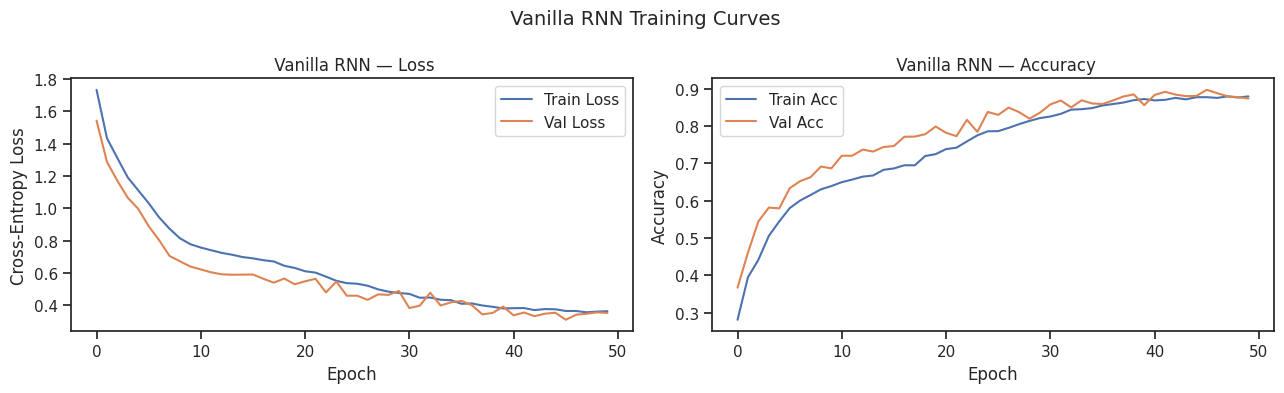

In [87]:
# ─────────────────────────────────────────────────────────────────
#  Training the  Vanilla RNN model with identical hyper-parameters
# ─────────────────────────────────────────────────────────────────

# Instantiate a new optimizer and scheduler for the RNN model
optimizer_rnn_ = torch.optim.AdamW(model_rnn_.parameters(), lr=LR, weight_decay=1e-4)
scheduler_rnn_ = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_rnn_, mode='min', factor=0.5, patience=5)

train_losses_rnn_ = []
val_losses_rnn_   = []
train_accs_rnn_   = []
val_accs_rnn_     = []

best_val_loss_rnn_ = float('inf')
best_weights_rnn_  = None

print('Training  Vanilla RNN ...\n')
for epoch in range(1, EPOCHS + 1):

    # Run one epoch of training
    train_loss, train_acc = run_epoch(model_rnn_, train_loader,
                                      optimizer_rnn_, criterion, is_training=True)
    # Run one epoch of validation
    val_loss,   val_acc   = run_epoch(model_rnn_, val_loader,
                                      None, criterion, is_training=False)

    # Store losses and accuracies
    train_losses_rnn_.append(train_loss)
    val_losses_rnn_.append(val_loss)
    train_accs_rnn_.append(train_acc)
    val_accs_rnn_.append(val_acc)

    # Step the learning rate scheduler based on validation loss
    scheduler_rnn_.step(val_loss)

    # Save the best model weights based on validation loss
    if val_loss < best_val_loss_rnn_:
        best_val_loss_rnn_ = val_loss
        best_weights_rnn_  = {k: v.cpu().clone()
                                  for k, v in model_rnn_.state_dict().items()}

    # Print progress at specified intervals (every 5 epochs or on the first epoch)
    if epoch % 5 == 0 or epoch == 1:
        print(f'Epoch {epoch:3d}/{EPOCHS} | '
              f'Train Loss: {train_loss:.4f}  Acc: {train_acc:.4f} | '
              f'Val Loss: {val_loss:.4f}  Acc: {val_acc:.4f}')


# Restore best weights before final evaluation
model_rnn_.load_state_dict(best_weights_rnn_)

# Save the best weights to disk
torch.save(best_weights_rnn_, 'rnn__best.pth')
print('\nSaved \u2192 rnn__best.pth')


# Plot training and validation loss curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Plot training and validation loss
axes[0].plot(train_losses_rnn_, label='Train Loss', color='#4c72b0')
axes[0].plot(val_losses_rnn_,   label='Val Loss',   color='#dd8452')
axes[0].set_title(' Vanilla RNN \u2014 Loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend()

# Plot training and validation accuracy
axes[1].plot(train_accs_rnn_, label='Train Acc', color='#4c72b0')
axes[1].plot(val_accs_rnn_,   label='Val Acc',   color='#dd8452')
axes[1].set_title(' Vanilla RNN \u2014 Accuracy')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.suptitle(' Vanilla RNN Training Curves', fontsize=14)
plt.tight_layout()
plt.show()

## Evaluate the  PyTorch RNN Model

After training, the  PyTorch RNN model is evaluated on the unseen test set. We will report its precision, recall, accuracy, and visualize its confusion matrix.

    Vanilla RNN — Test Set Evaluation
                    precision    recall  f1-score   support

           WALKING     0.8997    0.9965    0.9456       288
  WALKING_UPSTAIRS     0.9707    0.8561    0.9098       271
WALKING_DOWNSTAIRS     0.9605    0.9720    0.9662       250
           SITTING     0.8717    0.8743    0.8730       342
          STANDING     0.8835    0.8711    0.8773       357
            LAYING     0.9946    1.0000    0.9973       369

          accuracy                         0.9275      1877
         macro avg     0.9301    0.9283    0.9282      1877
      weighted avg     0.9285    0.9275    0.9271      1877

Activity                Precision   Recall
---------------------------------------------
WALKING                 0.8997      0.9965
WALKING_UPSTAIRS        0.9707      0.8561
WALKING_DOWNSTAIRS      0.9605      0.9720
SITTING                 0.8717      0.8743
STANDING                0.8835      0.8711
LAYING                  0.9946      1.0000


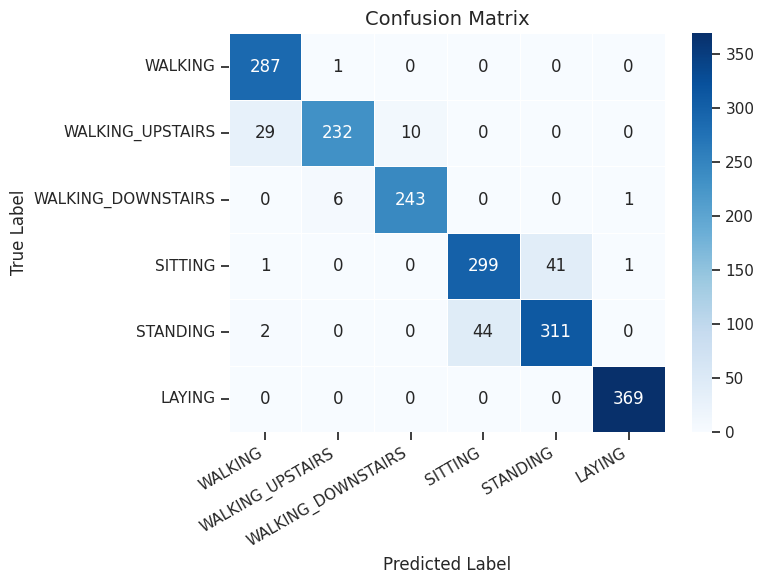

In [88]:
# ─────────────────────────────────────────────────────────────────
#  Evaluate the best  Vanilla RNN on the held-out test set.
# ─────────────────────────────────────────────────────────────────

print('=' * 55)
print('    Vanilla RNN — Test Set Evaluation')
print('=' * 55)

# Use the already defined `evaluate_on_test` function
rnn__preds, rnn_true_labels = evaluate_on_test(
    model_rnn_, test_loader, ACTIVITY_NAMES)


##  PyTorch LSTM Model

This section implements an LSTM model using PyTorch's optimized `nn.LSTM` layer. We will use a similar architecture to the GRU models (`HIDDEN_SIZE = 64`, `NUM_LAYERS = 2`, `DROPOUT = 0.4`) to facilitate a fair comparison. The `nn.LSTM` layer returns both the output for each time step and the final hidden and cell states. For classification, we are interested in the final hidden state of the last layer.

In [89]:
# ─────────────────────────────────────────────────────────────────
#  This section defines an LSTM model using PyTorch's
#  nn.LSTM layer. It mirrors the architecture of the previous GRU
#  implementations for consistent comparison.
# ─────────────────────────────────────────────────────────────────

import torch
from typing import Tuple

class LSTM(nn.Module):
    """
    LSTM model using PyTorch's  nn.LSTM layer.
    Architecture mirrors GRUScratch and GRU for comparison.
    """
    def __init__(self, input_size: int,
                 hidden_size: int,
                 num_layers: int,
                 num_classes: int,
                 dropout: float = 0.3):
        # Call the constructor of the parent class (nn.Module)
        super().__init__()
        # Define the LSTM layer
        self.lstm = nn.LSTM(
            input_size=input_size,         # The number of expected features in the input `x`
            hidden_size=hidden_size,       # The number of features in the hidden state `h`
            num_layers=num_layers,         # Number of recurrent layers
            batch_first=True,              # Input and output tensors are provided as (batch, seq, feature)
            dropout=dropout if num_layers > 1 else 0.0 # Dropout applied to the output of each LSTM layer except the last
        )
        # Define a dropout layer to be applied before the final classification layer
        self.dropout = nn.Dropout(dropout)
        # Define the final fully connected layer for classification
        self.fc_out = nn.Linear(hidden_size, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Forward pass for the LSTM model.
        x : (batch_size, seq_len, input_size) - Input tensor
        We only need the final hidden state, not all time-step outputs.
        """
        # Pass input through the LSTM layer. The second return value `(h_n, c_n)`
        # contains the final hidden state and cell state for each layer.
        lstm_out, (h_n, c_n) = self.lstm(x)

        # h_n has shape (num_layers, batch_size, hidden_size).
        # We need the hidden state of the last layer for classification.
        # h_n[-1, :, :] gets the last layer's final hidden states for all batches.
        last_hidden = h_n[-1, :, :]

        # Apply dropout to the final hidden state before the classification layer
        out = self.dropout(last_hidden)
        # Pass the processed hidden state through the final linear layer to get logits
        logits = self.fc_out(out)
        return logits

    def forward_for_visualization(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        """
        Forward pass that returns intermediate states for visualization.
        Returns:
            - lstm_out: Hidden states for all timesteps of the LAST layer (batch, seq_len, hidden_size)
            - h_n: Final hidden state for ALL layers (num_layers, batch, hidden_size)
            - c_n: Final cell state for ALL layers (num_layers, batch, hidden_size)
        """
        lstm_out, (h_n, c_n) = self.lstm(x)
        return lstm_out, h_n, c_n

# Instantiate the  LSTM model with the predefined hyperparameters
model_lstm_ = LSTM(
    input_size=INPUT_SIZE,       # 9 sensor channels
    hidden_size=HIDDEN_SIZE,     # 64 hidden units
    num_layers=NUM_LAYERS,       # 2 LSTM layers
    num_classes=NUM_CLASSES,     # 6 activity classes
    dropout=DROPOUT              # 0.4 dropout rate
).to(device) # Move the model to the appropriate device (CPU/GPU)

# Calculate and print the total number of trainable parameters in the model
total_params_lstm_ = sum(p.numel() for p in model_lstm_.parameters() if p.requires_grad)
print(f'Model architecture ( LSTM):\n{model_lstm_}')
print(f'\nTotal trainable parameters ( LSTM): {total_params_lstm_:,}')

Model architecture ( LSTM):
LSTM(
  (lstm): LSTM(9, 64, num_layers=2, batch_first=True, dropout=0.4)
  (dropout): Dropout(p=0.4, inplace=False)
  (fc_out): Linear(in_features=64, out_features=6, bias=True)
)

Total trainable parameters ( LSTM): 52,870


## Train the  PyTorch LSTM Model

We will now train the `LSTM` model using the same training loop and hyperparameters as the previous models. This will allow for a fair comparison of their learning curves and final performance.

Training  LSTM ...

Epoch   1/50 | Train Loss: 1.7574  Acc: 0.3073 | Val Loss: 1.6491  Acc: 0.3860
Epoch   5/50 | Train Loss: 1.1044  Acc: 0.5054 | Val Loss: 0.9992  Acc: 0.5611
Epoch  10/50 | Train Loss: 0.7177  Acc: 0.6403 | Val Loss: 0.6061  Acc: 0.6912
Epoch  15/50 | Train Loss: 0.6335  Acc: 0.7043 | Val Loss: 0.5970  Acc: 0.7155
Epoch  20/50 | Train Loss: 0.5104  Acc: 0.7898 | Val Loss: 0.5340  Acc: 0.7969
Epoch  25/50 | Train Loss: 0.3655  Acc: 0.8878 | Val Loss: 0.4145  Acc: 0.8593
Epoch  30/50 | Train Loss: 0.2532  Acc: 0.9182 | Val Loss: 0.3603  Acc: 0.8884
Epoch  35/50 | Train Loss: 0.1984  Acc: 0.9303 | Val Loss: 0.3623  Acc: 0.8879
Epoch  40/50 | Train Loss: 0.1683  Acc: 0.9368 | Val Loss: 0.3492  Acc: 0.8974
Epoch  45/50 | Train Loss: 0.1565  Acc: 0.9380 | Val Loss: 0.3703  Acc: 0.8900
Epoch  50/50 | Train Loss: 0.1375  Acc: 0.9440 | Val Loss: 0.3608  Acc: 0.9022

Saved → lstm__best.pth


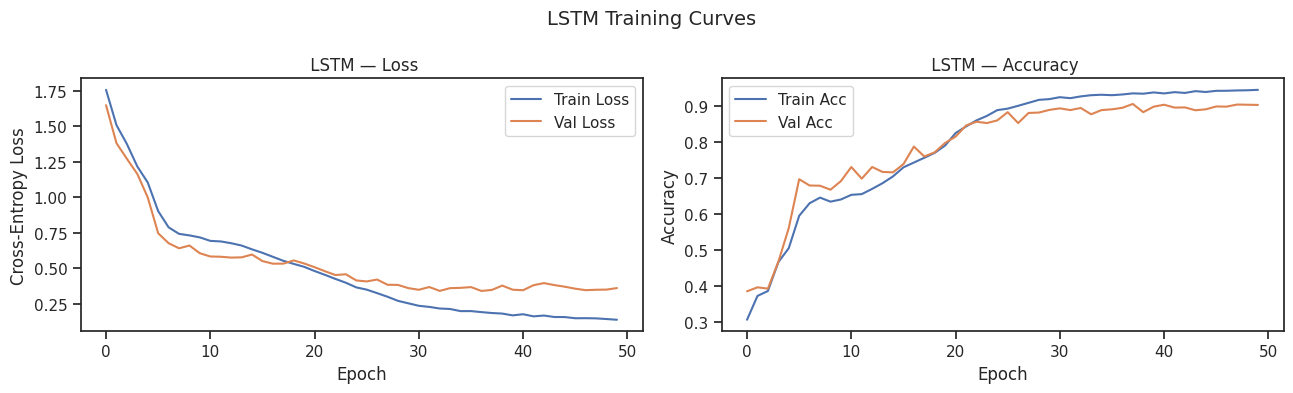

In [90]:
# ─────────────────────────────────────────────────────────────────
#  Training the  LSTM model with identical hyper-parameters
# ─────────────────────────────────────────────────────────────────

# Instantiate a new optimizer and scheduler for the LSTM model
optimizer_lstm_ = torch.optim.AdamW(model_lstm_.parameters(), lr=LR, weight_decay=1e-4)
scheduler_lstm_ = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_lstm_, mode='min', factor=0.5, patience=5)

train_losses_lstm = []
val_losses_lstm   = []
train_accs_lstm   = []
val_accs_lstm     = []

best_val_loss_lstm = float('inf')
best_weights_lstm  = None

print('Training  LSTM ...\n')
for epoch in range(1, EPOCHS + 1):

    # Run one epoch of training
    train_loss, train_acc = run_epoch(model_lstm_, train_loader,
                                      optimizer_lstm_, criterion, is_training=True)
    # Run one epoch of validation
    val_loss,   val_acc   = run_epoch(model_lstm_, val_loader,
                                      None, criterion, is_training=False)

    # Store losses and accuracies
    train_losses_lstm.append(train_loss)
    val_losses_lstm.append(val_loss)
    train_accs_lstm.append(train_acc)
    val_accs_lstm.append(val_acc)

    # Step the learning rate scheduler based on validation loss
    scheduler_lstm_.step(val_loss)

    # Save the best model weights based on validation loss
    if val_loss < best_val_loss_lstm:
        best_val_loss_lstm = val_loss
        best_weights_lstm  = {k: v.cpu().clone()
                                  for k, v in model_lstm_.state_dict().items()}

    # Print progress at specified intervals (every 5 epochs or on the first epoch)
    if epoch % 5 == 0 or epoch == 1:
        print(f'Epoch {epoch:3d}/{EPOCHS} | '
              f'Train Loss: {train_loss:.4f}  Acc: {train_acc:.4f} | '
              f'Val Loss: {val_loss:.4f}  Acc: {val_acc:.4f}')


# Restore best weights before final evaluation
model_lstm_.load_state_dict(best_weights_lstm)

# Save the best weights to disk
torch.save(best_weights_lstm, 'lstm__best.pth')
print('\nSaved → lstm__best.pth')


# ── Plot training and validation loss curves ─────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Plot training and validation loss
axes[0].plot(train_losses_lstm, label='Train Loss', color='#4c72b0')
axes[0].plot(val_losses_lstm,   label='Val Loss',   color='#dd8452')
axes[0].set_title(' LSTM — Loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend()

# Plot training and validation accuracy
axes[1].plot(train_accs_lstm, label='Train Acc', color='#4c72b0')
axes[1].plot(val_accs_lstm,   label='Val Acc',   color='#dd8452')
axes[1].set_title(' LSTM — Accuracy')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.suptitle('LSTM Training Curves', fontsize=14)
plt.tight_layout()
plt.show()

## Evaluate the LSTM Model

After training, the  PyTorch LSTM model is evaluated on the unseen test set. We will report its precision, recall, accuracy, and visualize its confusion matrix, similar to how the GRU models were evaluated.

LSTM — Test Set Evaluation
                    precision    recall  f1-score   support

           WALKING     0.9658    0.9792    0.9724       288
  WALKING_UPSTAIRS     0.9775    0.9631    0.9703       271
WALKING_DOWNSTAIRS     0.9728    1.0000    0.9862       250
           SITTING     0.8211    0.8860    0.8523       342
          STANDING     0.8824    0.7983    0.8382       357
            LAYING     1.0000    1.0000    1.0000       369

          accuracy                         0.9323      1877
         macro avg     0.9366    0.9378    0.9366      1877
      weighted avg     0.9329    0.9323    0.9320      1877

Activity                Precision   Recall
---------------------------------------------
WALKING                 0.9658      0.9792
WALKING_UPSTAIRS        0.9775      0.9631
WALKING_DOWNSTAIRS      0.9728      1.0000
SITTING                 0.8211      0.8860
STANDING                0.8824      0.7983
LAYING                  1.0000      1.0000


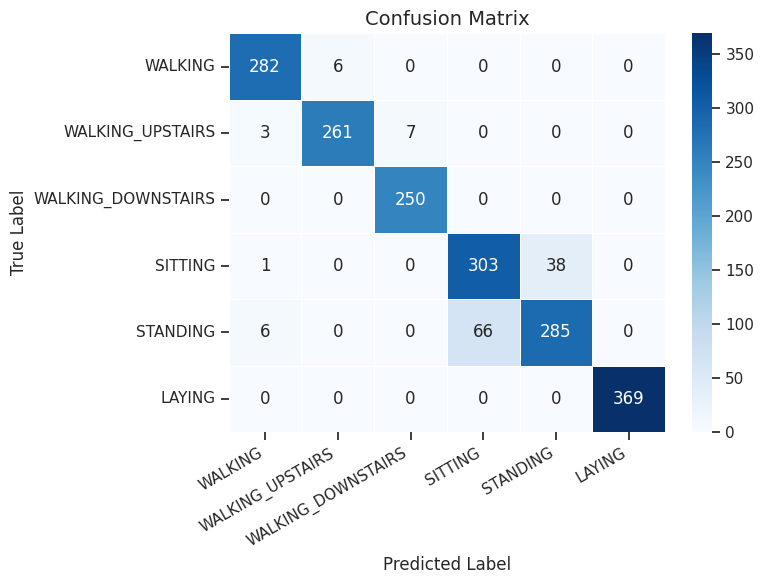

In [91]:
# ─────────────────────────────────────────────────────────────────
#  Evaluate the best  LSTM on the held-out test set.
# ─────────────────────────────────────────────────────────────────

print('=' * 55)
print('LSTM — Test Set Evaluation')
print('=' * 55)

# Use the already defined `evaluate_on_test` function
lstm__preds, _ = evaluate_on_test(
    model_lstm_, test_loader, ACTIVITY_NAMES)


## Inference Time Analysis

We will measure the average inference time per sample for both the RNN and LSTM models on the test set. This metric is crucial for understanding the computational efficiency of each model.

In [92]:
# ─────────────────────────────────────────────────────────────────
#  Measure average inference time per sample for RNN and LSTM models.
# ─────────────────────────────────────────────────────────────────

import time

def measure_inference_time(model, loader):
    """
    Measures the average inference time per sample for a given model and DataLoader.

    Args:
        model (nn.Module): The trained neural network model.
        loader (DataLoader): The DataLoader for the test dataset.

    Returns:
        float: Average inference time per sample in milliseconds.
    """
    model.eval() # Set the model to evaluation mode
    total_time = 0.0
    total_samples = 0

    with torch.no_grad(): # Disable gradient computation
        for X_batch, _ in loader:
            X_batch = X_batch.to(device) # Move batch to device

            start_time = time.perf_counter() # Start time measurement
            _ = model(X_batch) # Perform forward pass
            end_time = time.perf_counter() # End time measurement

            total_time += (end_time - start_time) # Accumulate time for the batch
            total_samples += X_batch.size(0) # Accumulate number of samples

    # Calculate average time per sample in milliseconds
    avg_time_ms = (total_time / total_samples) * 1000
    return avg_time_ms

# Measure inference time for  RNN
rnn_inference_time = measure_inference_time(model_rnn_, test_loader)
print(f'Average inference time per sample (RNN): {rnn_inference_time:.4f} ms')

# Measure inference time for  LSTM
lstm_inference_time = measure_inference_time(model_lstm_, test_loader)
print(f'Average inference time per sample (LSTM): {lstm_inference_time:.4f} ms')


Average inference time per sample (RNN): 0.0068 ms
Average inference time per sample (LSTM): 0.0066 ms


## Model Performance Summary

This table summarizes the key performance metrics for the  RNN and  LSTM models, including trainable parameters, inference time, test set accuracy, precision, and recall. This allows for a direct comparison of their efficiency and effectiveness.

In [93]:
# ─────────────────────────────────────────────────────────────────
#  Compile and display a summary table of model performances.
# ─────────────────────────────────────────────────────────────────

# Calculate overall accuracy for RNN
rnn_accuracy = (rnn__preds == rnn_true_labels).mean()

# Calculate overall accuracy for LSTM
lstm_accuracy = (lstm__preds == rnn_true_labels).mean()

# Get average precision and recall for RNN (macro average for multi-class)
rnn_precision_avg = precision_score(rnn_true_labels, rnn__preds, average='macro')
rnn_recall_avg    = recall_score(rnn_true_labels, rnn__preds, average='macro')

# Get average precision and recall for LSTM (macro average for multi-class)
lstm_precision_avg = precision_score(rnn_true_labels, lstm__preds, average='macro')
lstm_recall_avg    = recall_score(rnn_true_labels, lstm__preds, average='macro')

# Create a dictionary to hold the summary data
summary_data = {
    'Metric': [
        '# Trainable Parameters',
        'Avg Inference Time (ms/sample)',
        'Test Set Accuracy',
        'Test Set Avg Precision (macro)',
        'Test Set Avg Recall (macro)'
    ],
    'RNN': [
        total_params_rnn_,
        rnn_inference_time,
        rnn_accuracy,
        rnn_precision_avg,
        rnn_recall_avg
    ],
    'LSTM': [
        total_params_lstm_,
        lstm_inference_time,
        lstm_accuracy,
        lstm_precision_avg,
        lstm_recall_avg
    ]
}

# Create a Pandas DataFrame from the summary data
performance_df = pd.DataFrame(summary_data)

# Format numerical columns for better readability
performance_df['RNN'] = performance_df['RNN'].apply(lambda x: f'{x:,.0f}' if isinstance(x, int) else f'{x:.4f}')
performance_df['LSTM'] = performance_df['LSTM'].apply(lambda x: f'{x:,.0f}' if isinstance(x, int) else f'{x:.4f}')

# Display the DataFrame
display(performance_df)


,Metric,RNN,LSTM
0,# Trainable Parameters,13510.0000,52870.0000
1,Avg Inference Time (ms/sample),0.0068,0.0066
2,Test Set Accuracy,0.9275,0.9323
3,Test Set Avg Precision (macro),0.9301,0.9366
4,Test Set Avg Recall (macro),0.9283,0.9378


## Visualize Test Set Predictions

Let's visualize some randomly chosen sensor data samples from the test set, along with the model's predictions and confidence scores. This helps us qualitatively assess how well the LSTM model is performing on individual samples.

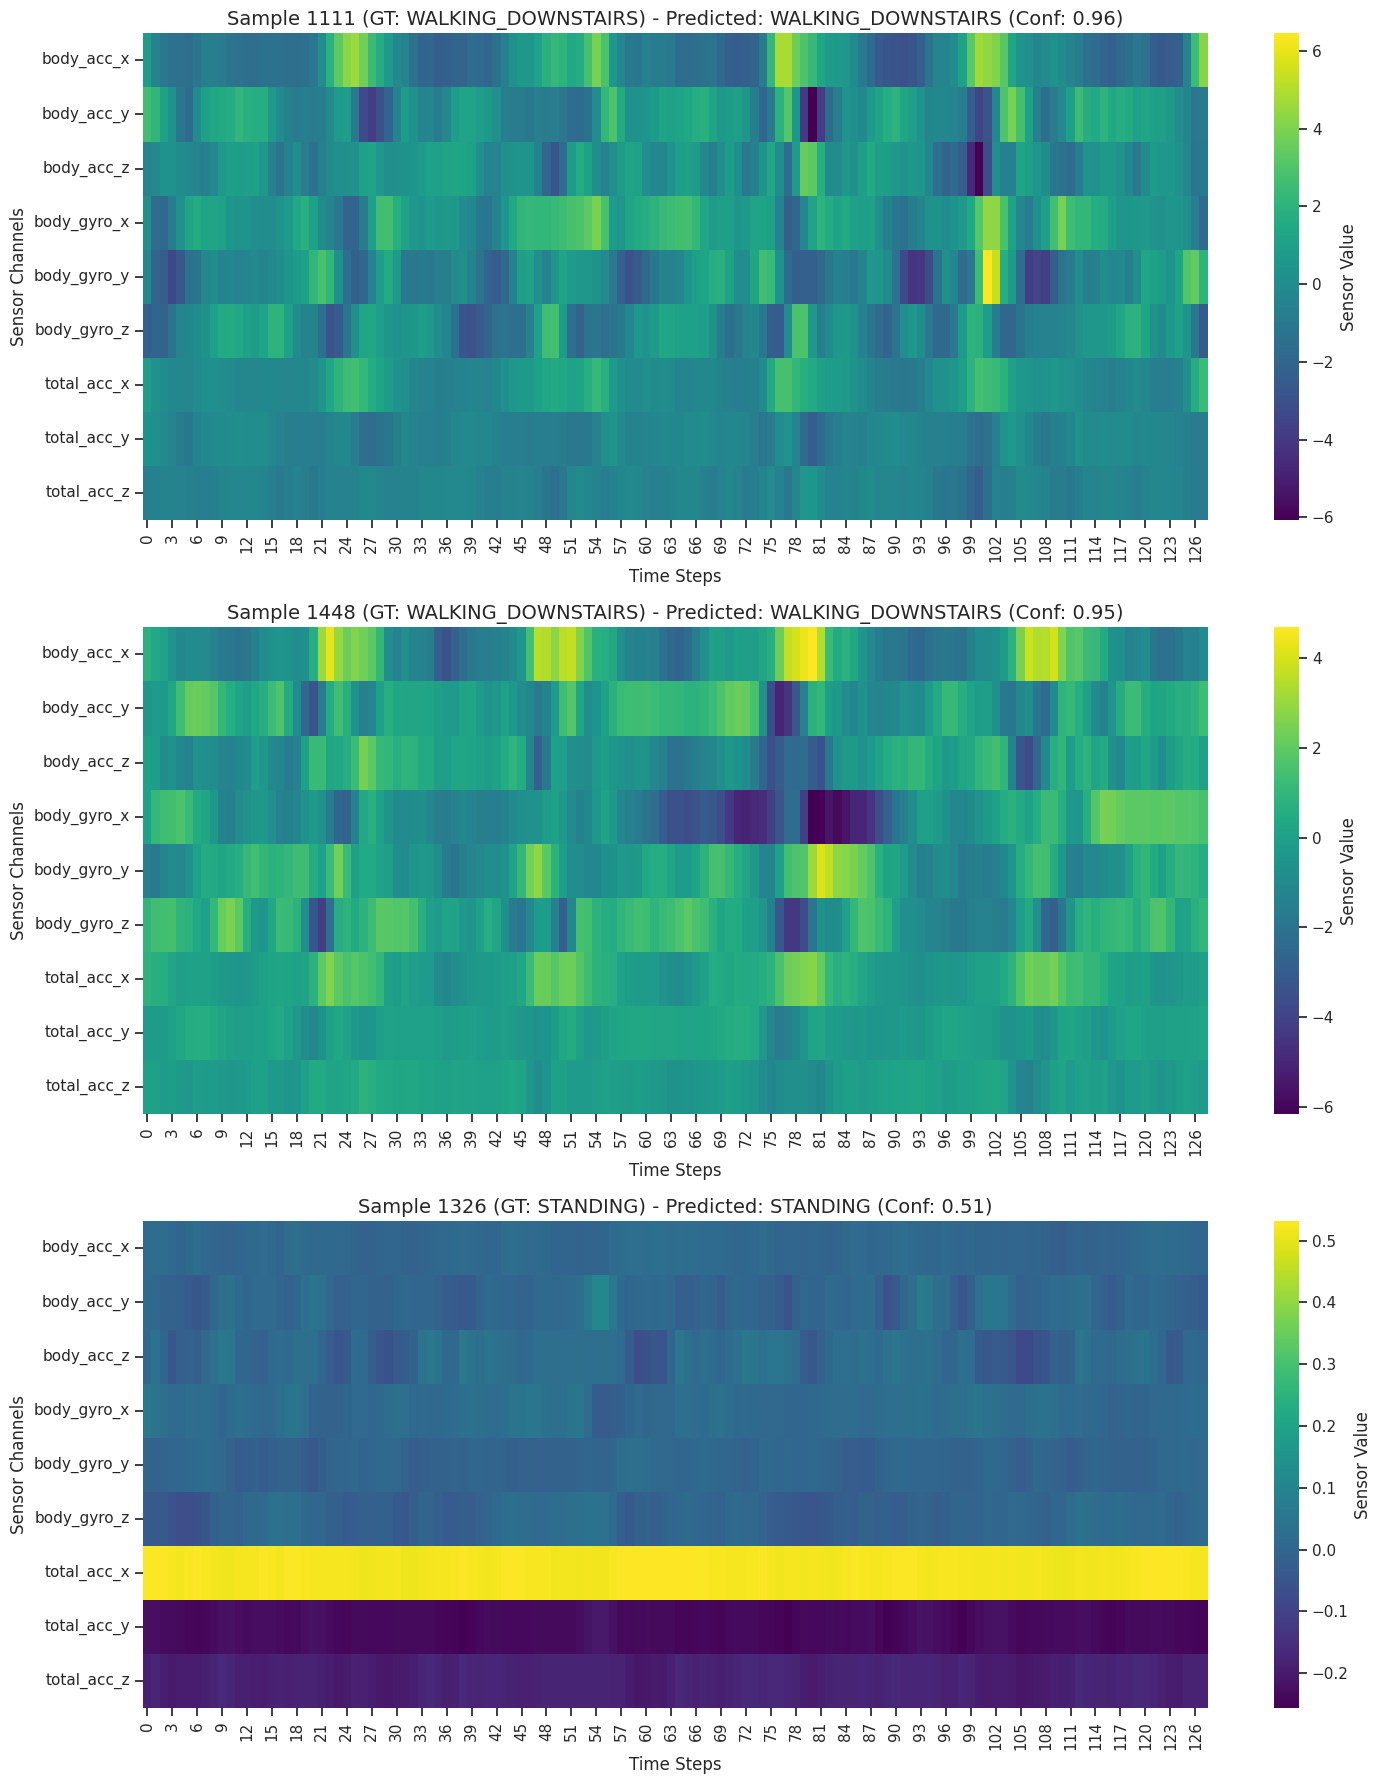

In [94]:
# ─────────────────────────────────────────────────────────────────
#  Visualize raw sensor data and model predictions for random samples.
# ─────────────────────────────────────────────────────────────────

# Get a few random indices from the test set for visualization
num_samples_to_visualize = 3 # Choose how many samples to display
random_test_indices = np.random.choice(len(X_test), num_samples_to_visualize, replace=False)

# Ensure model is in evaluation mode
model_lstm_.eval()

plt.figure(figsize=(15, 6 * num_samples_to_visualize))

for i, sample_idx in enumerate(random_test_indices):
    # Extract a single sample and its label from the original (standardized) test data
    sample_data_X = torch.tensor(X_test[sample_idx], dtype=torch.float32).unsqueeze(0).to(device) # Add batch dimension
    sample_data_y = y_test[sample_idx]

    with torch.no_grad():
        logits = model_lstm_(sample_data_X) # Get model prediction (logits)
        probabilities = torch.softmax(logits, dim=1) # Convert logits to probabilities
        predicted_prob, predicted_class_idx = torch.max(probabilities, dim=1) # Get max probability and its index

    # Map numerical labels back to activity names
    ground_truth_activity = ACTIVITY_NAMES[sample_data_y + 1] # Add 1 because ACTIVITY_NAMES is 1-indexed
    predicted_activity = ACTIVITY_NAMES[predicted_class_idx.item() + 1]

    # Plot the sensor data for the chosen sample
    plt.subplot(num_samples_to_visualize, 1, i + 1)
    sns.heatmap(
        sample_data_X.squeeze(0).cpu().numpy().T, # Remove batch dim, transpose to (features, timesteps)
        cmap='viridis', # Color map for heatmap
        cbar_kws={'label': 'Sensor Value'},
        yticklabels=SIGNAL_NAMES # Label y-axis with sensor names
    )
    plt.title(
        f'Sample {sample_idx} (GT: {ground_truth_activity}) - Predicted: {predicted_activity} (Conf: {predicted_prob.item():.2f})',
        fontsize=14
    )
    plt.xlabel('Time Steps') # X-axis label
    plt.ylabel('Sensor Channels') # Y-axis label

plt.tight_layout()
plt.show()


# LSTM Internal State Visualization

This section visualizes the internal states of the trained LSTM model for a randomly chosen utterance from the test set. We aim to understand how the model processes the sequential input by inspecting its hidden and cell states.

**Note on PyTorch `nn.LSTM` outputs:**
PyTorch's `nn.LSTM` module, when `batch_first=True`, returns two main outputs:
1.  `output`: This tensor has a shape of `(batch_size, seq_len, hidden_size)`. It represents the hidden states (`h_t`) for *each timestep* but *only for the last layer* of the LSTM. This directly fits the `d x T` heatmap visualization (where `d` is `hidden_size` and `T` is `seq_len`).
2.  `(h_n, c_n)`: These tensors have a shape of `(num_layers, batch_size, hidden_size)`. They represent the *final* hidden state (`h_n`) and cell state (`c_n`) for *each layer* at the *last timestep*. Since these are vectors (of size `hidden_size`), we will visualize them as a `1 x d` heatmap, clearly indicating they are the final states for their respective layers, rather than sequences over time.

Due to this structure, obtaining the hidden or cell states for *all timesteps* for *intermediate layers* is not directly supported by `nn.LSTM` without a custom loop or re-implementing the LSTM cell logic. Therefore, we will visualize the following accessible states:

*   **Raw Input Data**: The original sensor readings (`input_size x seq_len`).
*   **Last Layer Hidden States (over time)**: The `output` from the LSTM (`hidden_size x seq_len`).
*   **Final Hidden State - Layer 1**: `h_n[0, 0, :]` (a vector of `hidden_size`).
*   **Final Hidden State - Last Layer**: `h_n[-1, 0, :]` (a vector of `hidden_size`).
*   **Final Cell State - Layer 1**: `c_n[0, 0, :]` (a vector of `hidden_size`).
*   **Final Cell State - Last Layer**: `c_n[-1, 0, :]` (a vector of `hidden_size`).

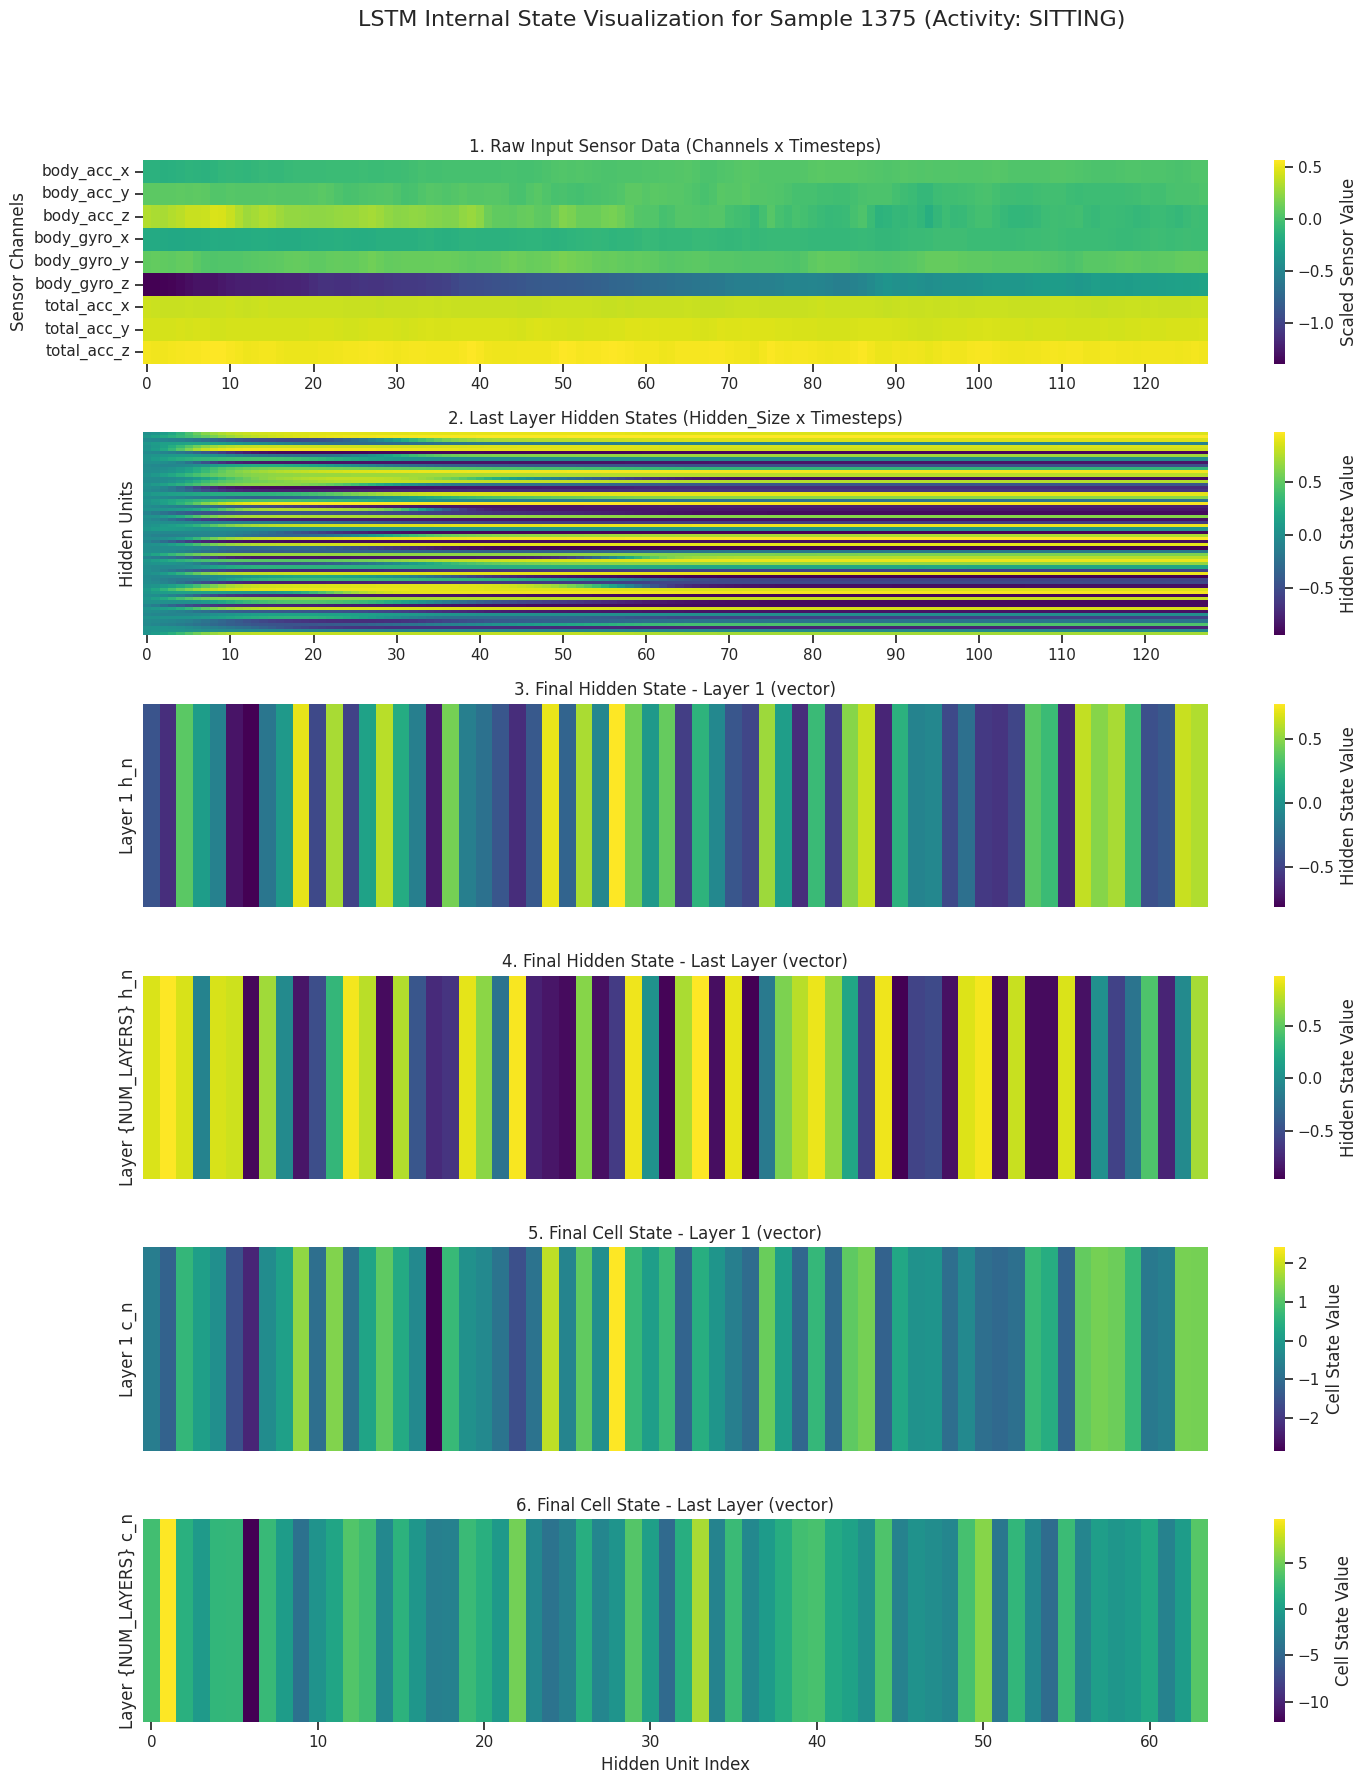

In [95]:
# ─────────────────────────────────────────────────────────────────
#  Visualize hidden and cell states of the LSTM for a random test sample.
# ─────────────────────────────────────────────────────────────────

# Select a random sample from the test dataset
random_idx = np.random.randint(0, len(test_dataset))
X_sample_test, y_sample_test = test_dataset[random_idx]

# Prepare the sample for the model (add batch dimension, move to device)
X_sample_test_model = X_sample_test.unsqueeze(0).to(device)

# Get LSTM internal states using the visualization forward pass
model_lstm_.eval()
with torch.no_grad():
    lstm_out, h_n, c_n = model_lstm_.forward_for_visualization(X_sample_test_model)

# Move tensors to CPU and convert to numpy for plotting
# lstm_out: (batch, seq_len, hidden_size) -> (hidden_size, seq_len) for heatmap
h_last_layer_over_time = lstm_out.squeeze(0).T.cpu().numpy()

# h_n, c_n: (num_layers, batch, hidden_size) -> (hidden_size,) for heatmap
h_final_l1   = h_n[0, 0, :].cpu().numpy()
h_final_last = h_n[-1, 0, :].cpu().numpy()
c_final_l1   = c_n[0, 0, :].cpu().numpy()
c_final_last = c_n[-1, 0, :].cpu().numpy()

# Prepare input data for visualization (input_size, seq_len)
input_data_vis = X_sample_test.T.cpu().numpy()


# Determine the number of plots needed
# 1 for input data + 1 for last layer hidden states + (NUM_LAYERS * 2) for final h/c states
# For NUM_LAYERS=2, this is 1 + 1 + (2 * 2) = 6 plots
# If we combine final h/c states per layer, it's 1 + 1 + 2 = 4 main plots

num_subplots = 6 # Input, last_layer_h_over_time, h_final_l1, h_final_last, c_final_l1, c_final_last
fig, axes = plt.subplots(num_subplots, 1, figsize=(15, 3 * num_subplots))

# Map numerical label back to activity name
ground_truth_activity = ACTIVITY_NAMES[y_sample_test.item() + 1]

fig.suptitle(f'LSTM Internal State Visualization for Sample {random_idx} (Activity: {ground_truth_activity})',
             fontsize=16, y=1.02)

# Plot 1: Raw Input Data
sns.heatmap(
    input_data_vis,
    cmap='viridis',
    ax=axes[0],
    cbar_kws={'label': 'Scaled Sensor Value'},
    yticklabels=SIGNAL_NAMES,
    xticklabels=10 # Show every 10th x-tick label
)
axes[0].set_title('1. Raw Input Sensor Data (Channels x Timesteps)')
axes[0].set_ylabel('Sensor Channels')

# Plot 2: Hidden States of the Last Layer (over time)
sns.heatmap(
    h_last_layer_over_time,
    cmap='viridis',
    ax=axes[1],
    cbar_kws={'label': 'Hidden State Value'},
    yticklabels=False, # Hide y-labels for brevity
    xticklabels=10 # Show every 10th x-tick label
)
axes[1].set_title('2. Last Layer Hidden States (Hidden_Size x Timesteps)')
axes[1].set_ylabel('Hidden Units')

# Plot 3: Final Hidden State - Layer 1
sns.heatmap(
    h_final_l1.reshape(1, -1), # Reshape to 1xhidden_size for heatmap
    cmap='viridis',
    ax=axes[2],
    cbar_kws={'label': 'Hidden State Value'},
    yticklabels=False, # No yticklabel for single row
    xticklabels=False # No x-ticklabels for final states
)
axes[2].set_title(f'3. Final Hidden State - Layer 1 (vector)')
axes[2].set_ylabel('Layer 1 h_n')

# Plot 4: Final Hidden State - Last Layer
sns.heatmap(
    h_final_last.reshape(1, -1), # Reshape to 1xhidden_size for heatmap
    cmap='viridis',
    ax=axes[3],
    cbar_kws={'label': 'Hidden State Value'},
    yticklabels=False,
    xticklabels=False
)
axes[3].set_title(f'4. Final Hidden State - Last Layer (vector)')
axes[3].set_ylabel('Layer {NUM_LAYERS} h_n')

# Plot 5: Final Cell State - Layer 1
sns.heatmap(
    c_final_l1.reshape(1, -1), # Reshape to 1xhidden_size for heatmap
    cmap='viridis',
    ax=axes[4],
    cbar_kws={'label': 'Cell State Value'},
    yticklabels=False,
    xticklabels=False
)
axes[4].set_title(f'5. Final Cell State - Layer 1 (vector)')
axes[4].set_ylabel('Layer 1 c_n')

# Plot 6: Final Cell State - Last Layer
sns.heatmap(
    c_final_last.reshape(1, -1), # Reshape to 1xhidden_size for heatmap
    cmap='viridis',
    ax=axes[5],
    cbar_kws={'label': 'Cell State Value'},
    yticklabels=False,
    xticklabels=10 # Show x-labels on the last subplot
)
axes[5].set_title(f'6. Final Cell State - Last Layer (vector)')
axes[5].set_xlabel('Hidden Unit Index')
axes[5].set_ylabel('Layer {NUM_LAYERS} c_n')

plt.tight_layout(rect=[0, 0.03, 1, 0.98]) # Adjust layout to prevent overlapping titles/labels
plt.show()

# References and Additional Learning Materials

### Recurrent Neural Networks (RNN & LSTM) & Advanced Visualization Guides
- **Visualizing RNNs**: [Resource Link](https://joshvarty.github.io/VisualizingRNNs/)
    * Explains and visualizes how hidden states and weights evolve dynamically over time steps, tracing specific neuron activations for sequence data.
- **Memorization in RNNs**: [Resource Link](https://distill.pub/2019/memorization-in-rnns/)
    * An interactive visual essay demonstrating how recurrent networks store and retrieve memory over long sequences, detailing cell state retention in LSTMs vs fast decay in standard RNNs.
- **A Visual Guide to Recurrent Neural Networks**: [Resource Link](https://www.analyticsvidhya.com/blog/2021/06/a-visual-guide-to-recurrent-neural-networks/)
    * An intuitive, visual-heavy tutorial explaining the core gating logic of RNN, LSTM, and GRU units, clarifying backpropagation and vanishing gradients.
- **Under the Hood of Recurrent Neural Networks**: [Resource Link](https://wandb.ai/authors/rnn-viz/reports/Under-the-Hood-of-Recurrent-Neural-Networks--VmlldzoyNTQ4MjY)
    * Explains how to monitor, log, and visualize gradients, weights, and hidden states dynamically during model training.
- **PyTorch RNN Tutorial**: [Resource Link](https://colab.research.google.com/github/dair-ai/pytorch_notebooks/blob/master/RNN_PT.ipynb)
    * A step-by-step interactive PyTorch notebook demonstrating tensor shape routing, embeddings, and code execution for recurrent neural networks.
- **Colah's Blog: Understanding LSTM Networks**: [Blog Link](https://colah.github.io/posts/2015-08-Understanding-LSTMs/)
    * The gold standard, beginner-friendly visual explanation of LSTMs and GRUs.
- **PyTorch Recurrent Layers Documentation**:
  - [`torch.nn.RNN`](https://pytorch.org/docs/stable/generated/torch.nn.RNN.html) - Documentation for standard RNN layers.
  - [`torch.nn.LSTM`](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html) - Documentation for LSTM layer gating and cell states.

### General Deep Learning & Preprocessing
- **Scikit-Learn Preprocessing**: [StandardScaler Guide](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
    * Explains why standard scaling is essential before training neural networks.
- **PyTorch DataLoader Tutorial**: [Dataloader Guide](https://pytorch.org/docs/stable/data.html)
    * Explains batching, shuffling, and custom datasets for beginners.